**CAPSTONE MODUL 3 : BIKE SHARING - IVAN SETYA ANANDA**

****
# **Business Understanding**
****

**Context:**
***
Bike-sharing systems represent a modern evolution of traditional bike rentals, automating the entire process from membership to rental and return. Users can effortlessly rent a bike from one station and return it to another
Focusing on the casual user segment—tourists, occasional riders, and non-regular commuters—offers substantial growth opportunities. Casual users typically seek flexibility and convenience, making them a lucrative market. The rich data generated by bike-sharing systems, including travel duration and station usage, provides valuable insights into urban mobility patterns. This data can be leveraged to enhance user experience, optimize operations, and drive targeted marketing strategies.


**Stakelhoders:**
***
Marketing Team ( Capital Bikeshare company)
 -  **Role:** Develop and suggest marketing campaigns to attract casual users.
 -  **Involvement:** Advertising, promotions, partnerships.


**Problem Statement:**
***
Despite a steady influx of casual users, our bike rental business has not fully capitalized on this market segment. We aim to identify the key factors influencing casual users' decision-making processes and develop targeted marketing and operational strategies to enhance their rental experience.


**Business Objective:**
***
Marketing Team Capital Bikeshare Company wants to know:
1.	Which Key Features are significant in predicting the casual shared bike demand
2.	How well those features describe the shared bike demand


In [1]:
# import the dataset
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from xgboost.sklearn import XGBRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline


import warnings
warnings.filterwarnings('ignore')

Matplotlib is building the font cache; this may take a moment.


In [2]:
bike = pd.read_csv('data_bike_sharing.csv')
bike

,dteday,hum,weathersit,holiday,season,atemp,temp,hr,casual,registered,cnt
0,2011-12-09,0.62,1,0,4,0.3485,0.36,16,24,226,250
1,2012-06-17,0.64,1,0,2,0.5152,0.54,4,2,16,18
2,2011-06-15,0.53,1,0,2,0.6212,0.62,23,17,90,107
3,2012-03-31,0.87,2,0,2,0.3485,0.36,8,19,126,145
4,2012-07-31,0.55,1,0,3,0.6970,0.76,18,99,758,857
...,...,...,...,...,...,...,...,...,...,...,...
12160,2012-01-25,0.75,1,0,1,0.2273,0.24,7,14,243,257
12161,2012-07-06,0.62,1,0,3,0.7424,0.78,0,39,63,102
12162,2012-02-20,0.60,2,1,1,0.2121,0.24,5,0,6,6
12163,2012-03-31,0.77,2,0,2,0.4242,0.42,2,14,55,69


***
# **Data Collection and Preprocessing**
***

## **Collect Data**

In [3]:
bike.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12165 entries, 0 to 12164
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dteday      12165 non-null  object 
 1   hum         12165 non-null  float64
 2   weathersit  12165 non-null  int64  
 3   holiday     12165 non-null  int64  
 4   season      12165 non-null  int64  
 5   atemp       12165 non-null  float64
 6   temp        12165 non-null  float64
 7   hr          12165 non-null  int64  
 8   casual      12165 non-null  int64  
 9   registered  12165 non-null  int64  
 10  cnt         12165 non-null  int64  
dtypes: float64(3), int64(7), object(1)
memory usage: 1.0+ MB


There is data type error for dteday column; it should be DateTime

There are data types error for weathersit, holiday, season, hr columns; it should be Category

## **Clean Data**

In [4]:
# percentage of missing values
missing_columns = (bike.isnull().sum())*100/len(bike)
missing_rows = (bike.isnull().sum(axis=1))*100/len(bike)
display(missing_columns,missing_rows)

dteday        0.0
hum           0.0
weathersit    0.0
holiday       0.0
season        0.0
atemp         0.0
temp          0.0
hr            0.0
casual        0.0
registered    0.0
cnt           0.0
dtype: float64

0        0.0
1        0.0
2        0.0
3        0.0
4        0.0
        ... 
12160    0.0
12161    0.0
12162    0.0
12163    0.0
12164    0.0
Length: 12165, dtype: float64

There are no missing values either in columns or rows.

<Axes: >

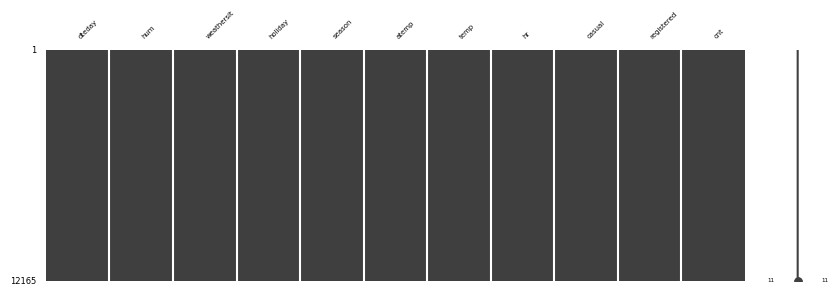

In [5]:
import missingno as msn
msn.matrix(bike,figsize=(10,3),fontsize=5)

In [6]:
# check duplicate
bike.duplicated().sum()

0

There are no duplicate values.

 ## **Feature Engineering**

In [7]:
bike['dteday'] = pd.to_datetime(bike['dteday'])
bike['day'] = bike['dteday'].dt.day_of_week
bike['month'] = bike['dteday'].dt.month

In [8]:
bike_new=bike[['hum','weathersit','holiday','season','temp','atemp','hr','cnt','day','month']]
bike_new.columns

Index(['hum', 'weathersit', 'holiday', 'season', 'temp', 'atemp', 'hr', 'cnt',
       'day', 'month'],
      dtype='object')

In [9]:
bike_new['season'].replace({1: 'Winter', 2: 'Spring', 3: 'Summer', 4: 'Fall'}, inplace=True)
bike_new['weathersit'].replace({1: 'Clear', 2: 'Mist', 3: 'Light Rain/Snow', 4: 'Heavy Rain/Snow'}, inplace=True)
bike_new['holiday'].replace({1:'Yes', 0:'No'}, inplace=True)

In [10]:
# cat_columns = bike_new[['weathersit','season','hr','holiday','day','month']]


# bike_new['season']=bike_new['season'].astype('object')
# bike_new['weathersit']=bike_new['weathersit'].astype('object')
# bike_new['month']=bike_new['month'].astype('object')
# bike_new['day']=bike_new['day'].astype('object')
# bike_new['hr']=bike_new['hr'].astype('object')
# bike_new['holiday']=bike_new['holiday'].astype('object')

In [11]:
bike_new.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12165 entries, 0 to 12164
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   hum         12165 non-null  float64
 1   weathersit  12165 non-null  object 
 2   holiday     12165 non-null  object 
 3   season      12165 non-null  object 
 4   temp        12165 non-null  float64
 5   atemp       12165 non-null  float64
 6   hr          12165 non-null  object 
 7   cnt         12165 non-null  int64  
 8   day         12165 non-null  object 
 9   month       12165 non-null  object 
dtypes: float64(3), int64(1), object(6)
memory usage: 950.5+ KB


 ## **Outlier Handling**

In [12]:
num_columns = bike_new[['hum','temp','atemp','cnt']]


In [13]:
num_columns.describe().loc[['max','50%','min','mean']]

,hum,temp,atemp,cnt
max,1.000000,1.000000,1.000000,970.000000
50%,0.620000,0.500000,0.484800,142.000000
min,0.000000,0.020000,0.000000,1.000000
mean,0.625451,0.498185,0.476996,189.271023


In [1]:
# Set up the plot
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Boxplots of Bike Sharing Data', fontsize=16)

# Flatten the axes array for easier iteration
axes = axes.flatten()

# Create boxplots using a for loop
for i, column in enumerate(num_columns):
    axes[i].boxplot(bike[column])
    axes[i].set_title(column)
    axes[i].set_ylabel('Values')

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [15]:
# Outliers for casual check
outliers = bike[bike['cnt'] >= 614]

# Count occurrences of each dteday
dteday_counts = outliers['dteday'].value_counts()

# Filter for dteday values that occur more than once
repeated_dtedays = dteday_counts[dteday_counts > 1].index

# Filter outliers for those dteday values
outliers_with_repeated_dtedays = outliers[outliers['dteday'].isin(repeated_dtedays)]
outliers_with_repeated_dtedays.sort_values(by='registered', ascending=False)

,dteday,hum,weathersit,holiday,season,atemp,temp,hr,casual,registered,cnt,day,month
989,2012-09-26,0.48,1,0,4,0.6667,0.74,17,77,876,953,2,9
8333,2012-10-24,0.47,1,0,4,0.6212,0.66,17,87,876,963,2,10
9118,2012-10-10,0.43,1,0,4,0.5455,0.58,17,91,857,948,2,10
12027,2012-10-16,0.39,1,0,4,0.5000,0.52,17,104,839,943,1,10
8901,2012-10-03,0.65,1,0,4,0.6515,0.70,17,84,833,917,2,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9621,2012-10-06,0.46,1,0,4,0.6212,0.60,15,279,341,620,5,10
6651,2012-03-17,0.53,1,0,1,0.6212,0.62,14,352,338,690,5,3
6317,2012-04-15,0.39,1,0,2,0.6515,0.72,16,286,330,616,6,4
3283,2012-05-19,0.30,1,0,2,0.6515,0.72,15,356,316,672,5,5


In [16]:
# Outliers for humidity check
outliers = bike[bike_new['hum'] <= 0.0500]
outliers

,dteday,hum,weathersit,holiday,season,atemp,temp,hr,casual,registered,cnt,day,month
345,2011-03-10,0.0,3,0,1,0.3939,0.38,7,1,36,37,3,3
871,2011-03-10,0.0,3,0,1,0.4394,0.44,15,3,11,14,3,3
1645,2011-03-10,0.0,3,0,1,0.3182,0.34,0,3,0,3,3,3
3239,2011-03-10,0.0,2,0,1,0.4394,0.44,17,2,109,111,3,3
3717,2011-03-10,0.0,2,0,1,0.3333,0.34,22,4,30,34,3,3
4924,2011-03-10,0.0,3,0,1,0.3333,0.36,6,0,12,12,3,3
7285,2011-03-10,0.0,3,0,1,0.3182,0.34,1,0,2,2,3,3
7760,2011-03-10,0.0,3,0,1,0.4242,0.42,12,4,30,34,3,3
8412,2011-03-10,0.0,3,0,1,0.3939,0.38,8,1,43,44,3,3
8960,2011-03-10,0.0,3,0,1,0.3485,0.34,23,1,26,27,3,3


In [17]:
results = {}

for col in num_columns:
    q3 = bike_new[col].describe().loc['75%']
    q1 = bike_new[col].describe().loc['25%']

    iqr = q3 - q1

    upper = q3 + 1.5 * iqr
    lower = q1 - 1.5 * iqr

    # Count outliers
    upper_outliers = (bike_new[col] > upper).sum()
    lower_outliers = (bike_new[col] < lower).sum()
    total_outliers = upper_outliers + lower_outliers

    # Calculate percentages
    total_count = len(bike_new[col])
    upper_percent = (upper_outliers / total_count) * 100
    lower_percent = (lower_outliers / total_count) * 100
    total_percent = (total_outliers / total_count) * 100

    results[col] = {
        'Upper fence': upper,
        'Lower fence': lower,
        'Upper outliers': upper_outliers,
        'Upper outliers %': upper_percent,
        'Lower outliers': lower_outliers,
        'Lower outliers %': lower_percent,
        'Total outliers': total_outliers,
        'Total outliers %': total_percent
    }
    
show_outliers = pd.DataFrame(results).T.sort_values(by='Total outliers', ascending=False)
show_outliers




,Upper fence,Lower fence,Upper outliers,Upper outliers %,Lower outliers,Lower outliers %,Total outliers,Total outliers %
cnt,645.00000,-323.00000,338.0,2.778463,0.0,0.000000,338.0,2.778463
hum,1.24500,0.00500,0.0,0.000000,14.0,0.115084,14.0,0.115084
temp,1.14000,-0.14000,0.0,0.000000,0.0,0.000000,0.0,0.000000
atemp,1.05305,-0.09855,0.0,0.000000,0.0,0.000000,0.0,0.000000


In [18]:
bike_new = bike_new[bike_new['hum'] >= 0.00500]
print(bike_new.shape)

bike_new = bike_new[bike_new['cnt'] <= 645.00000]
print(bike_new.shape)

(12151, 10)
(11813, 10)


In [19]:
# # Set up the plot
# fig, axes = plt.subplots(2, 2, figsize=(15, 10))
# fig.suptitle('Boxplots of Bike Sharing Data', fontsize=16)

# # Flatten the axes array for easier iteration
# axes = axes.flatten()

# # Create boxplots using a for loop
# for i, column in enumerate(num_columns):
#     axes[i].boxplot(bike_new[column])
#     axes[i].set_title(column)
#     axes[i].set_ylabel('Values')

# # Adjust layout and display the plot
# plt.tight_layout()
# plt.show()

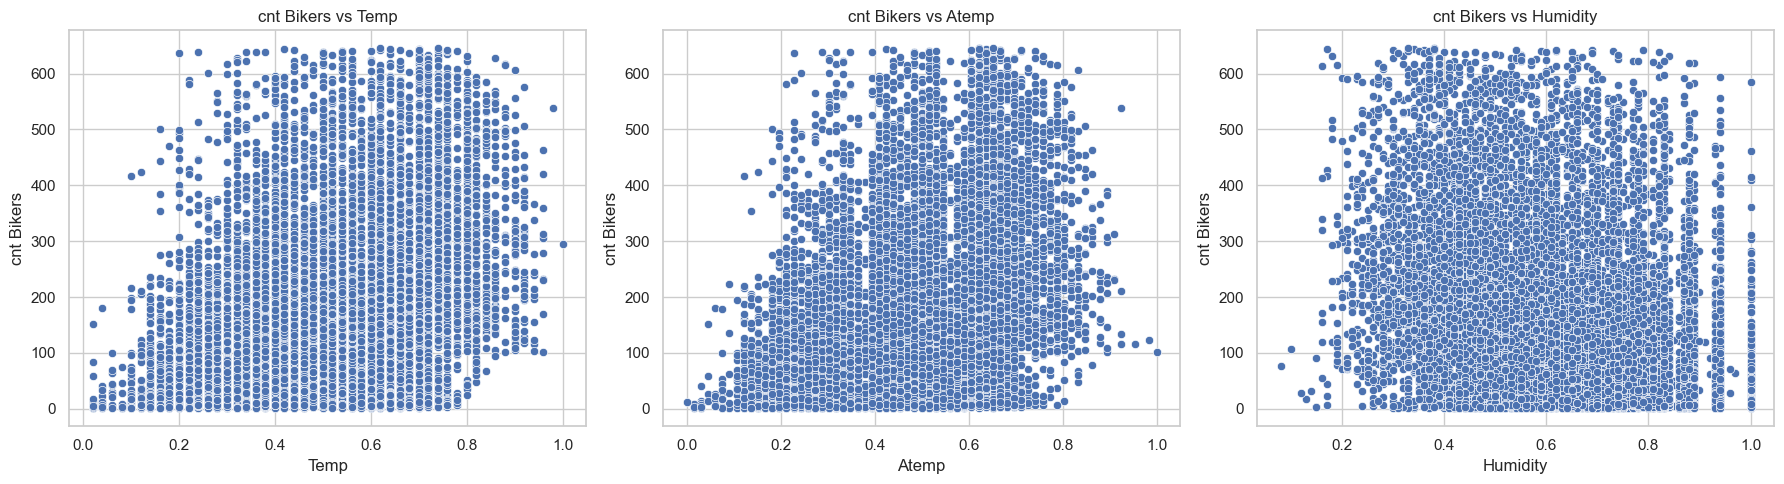

In [20]:

# Set up the plotting environment
sns.set(style="whitegrid")

# Create scatter plots for cnt bikers against temp, atemp, and hum
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Scatter plot for temp vs cnt
sns.scatterplot(ax=axes[0], x='temp', y='cnt', data=bike_new)
axes[0].set_title('cnt Bikers vs Temp')
axes[0].set_xlabel('Temp')
axes[0].set_ylabel('cnt Bikers')

# Scatter plot for atemp vs cnt
sns.scatterplot(ax=axes[1], x='atemp', y='cnt', data=bike_new)
axes[1].set_title('cnt Bikers vs Atemp')
axes[1].set_xlabel('Atemp')
axes[1].set_ylabel('cnt Bikers')

# Scatter plot for hum vs cnt
sns.scatterplot(ax=axes[2], x='hum', y='cnt', data=bike_new)
axes[2].set_title('cnt Bikers vs Humidity')
axes[2].set_xlabel('Humidity')
axes[2].set_ylabel('cnt Bikers')

# Show the plots
plt.tight_layout()
plt.show()

In [21]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['temp']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.160
Model:                            OLS   Adj. R-squared:                  0.160
Method:                 Least Squares   F-statistic:                     2253.
Date:                Wed, 10 Jul 2024   Prob (F-statistic):               0.00
Time:                        20:03:22   Log-Likelihood:                -75379.
No. Observations:               11813   AIC:                         1.508e+05
Df Residuals:                   11811   BIC:                         1.508e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         13.1420      3.623      3.627      0.0

In [22]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['atemp']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.157
Model:                            OLS   Adj. R-squared:                  0.157
Method:                 Least Squares   F-statistic:                     2206.
Date:                Wed, 10 Jul 2024   Prob (F-statistic):               0.00
Time:                        20:03:22   Log-Likelihood:                -75399.
No. Observations:               11813   AIC:                         1.508e+05
Df Residuals:                   11811   BIC:                         1.508e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.0520      3.858      0.791      0.4

In [23]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['hum']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.108
Model:                            OLS   Adj. R-squared:                  0.108
Method:                 Least Squares   F-statistic:                     1426.
Date:                Wed, 10 Jul 2024   Prob (F-statistic):          8.94e-295
Time:                        20:03:22   Log-Likelihood:                -75737.
No. Observations:               11813   AIC:                         1.515e+05
Df Residuals:                   11811   BIC:                         1.515e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        342.1806      4.670     73.265      0.0

In [24]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['temp','atemp']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.160
Model:                            OLS   Adj. R-squared:                  0.160
Method:                 Least Squares   F-statistic:                     1127.
Date:                Wed, 10 Jul 2024   Prob (F-statistic):               0.00
Time:                        20:03:22   Log-Likelihood:                -75378.
No. Observations:               11813   AIC:                         1.508e+05
Df Residuals:                   11810   BIC:                         1.508e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         11.0452      4.049      2.728      0.0

In [25]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['temp','hum']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.254
Model:                            OLS   Adj. R-squared:                  0.253
Method:                 Least Squares   F-statistic:                     2006.
Date:                Wed, 10 Jul 2024   Prob (F-statistic):               0.00
Time:                        20:03:22   Log-Likelihood:                -74683.
No. Observations:               11813   AIC:                         1.494e+05
Df Residuals:                   11810   BIC:                         1.494e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        177.6390      5.476     32.440      0.0

In [26]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['atemp','hum']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.255
Model:                            OLS   Adj. R-squared:                  0.255
Method:                 Least Squares   F-statistic:                     2021.
Date:                Wed, 10 Jul 2024   Prob (F-statistic):               0.00
Time:                        20:03:22   Log-Likelihood:                -74672.
No. Observations:               11813   AIC:                         1.493e+05
Df Residuals:                   11810   BIC:                         1.494e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        169.2842      5.570     30.393      0.0

In [27]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['temp','atemp','hum']]))
result = sm_lm.fit()

In [28]:
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.255
Model:                            OLS   Adj. R-squared:                  0.255
Method:                 Least Squares   F-statistic:                     1350.
Date:                Wed, 10 Jul 2024   Prob (F-statistic):               0.00
Time:                        20:03:22   Log-Likelihood:                -74669.
No. Observations:               11813   AIC:                         1.493e+05
Df Residuals:                   11809   BIC:                         1.494e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        170.9548      5.613     30.457      0.0

In [29]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
def calc_vif(X):

    # Calculating VIF
    vif = pd.DataFrame()
    vif["variables"] = X.columns
    vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

    return(vif)

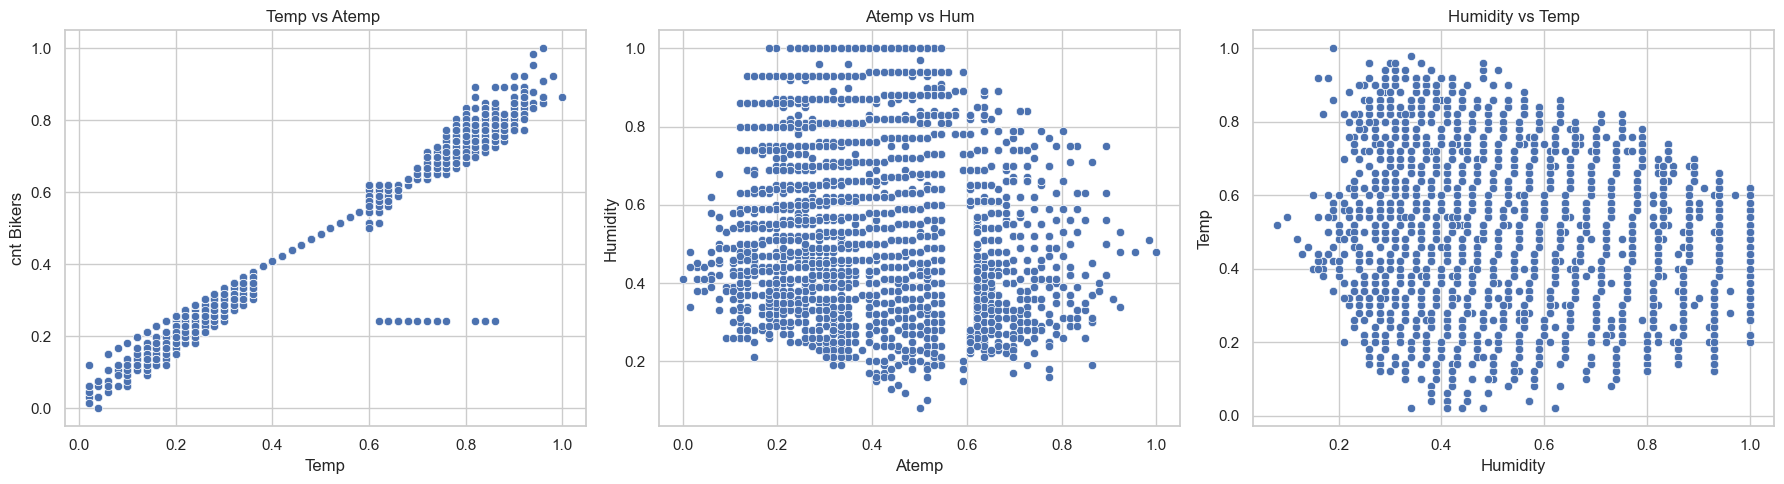

In [30]:
# Set up the plotting environment
sns.set(style="whitegrid")

# Create scatter plots for cnt bikers against temp, atemp, and hum
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Scatter plot for temp vs cnt
sns.scatterplot(ax=axes[0], x='temp', y='atemp', data=bike_new)
axes[0].set_title('Temp vs Atemp ')
axes[0].set_xlabel('Temp')
axes[0].set_ylabel('cnt Bikers')

# Scatter plot for atemp vs cnt
sns.scatterplot(ax=axes[1], x='atemp', y='hum', data=bike_new)
axes[1].set_title('Atemp vs Hum')
axes[1].set_xlabel('Atemp')
axes[1].set_ylabel('Humidity')

# Scatter plot for hum vs cnt
sns.scatterplot(ax=axes[2], x='hum', y='temp', data=bike_new)
axes[2].set_title('Humidity vs Temp')
axes[2].set_xlabel('Humidity')
axes[2].set_ylabel('Temp')

# Show the plots
plt.tight_layout()
plt.show()


In [31]:
calc_vif(bike_new[['temp','atemp']])

,variables,VIF
0,temp,271.514749
1,atemp,271.514749


In [32]:
calc_vif(bike_new[['temp','hum']])

,variables,VIF
0,temp,4.636778
1,hum,4.636778


In [33]:
calc_vif(bike_new[['atemp','hum']])

,variables,VIF
0,atemp,5.047622
1,hum,5.047622


In [34]:
calc_vif(bike_new[['temp','atemp','hum']])

,variables,VIF
0,temp,299.112587
1,atemp,325.615551
2,hum,5.560682



<center>

| F | p-value | R-squared | Adj. R-squared | X1 | X2 | X3 | VIF |
|---------|-------------------------|------------------------|--------------|--------------|--------------|--------------|--------------|
| 4320    | 0.00               | 0.277              | 0.276    | X    |     |     | 1.00    |
| 4127    | 0.00               | 0.267               | 0.267    |     | X    |     |1.00   |
| 0.267  | 0.00                | 0.128               | 0.128    |     |     | X     | 1.00    |
| 2162    | 0.00                | 0.277               | 0.277    | X    | X    |     | 270.27   |
| 3691    | 0.00                | 0.395               | 0.395   | X    |     | X    | 4.77    |
| 3644    | 0.00                | 0.392               | 0.392  |     | X    | X    | 5.19    |
| 2465    | 0.00                | 0.396               | 0.395 |  X   |  X   |  X   | below   |
|     |     |     |     | 296.13    | 322.4    | 5.69    |     |
<center>

# Model Improvement (Dummy Variables)

In [35]:
# cat_columns = bike_new[['weathersit','season','hr','holiday','day','month']]


# bike_new['season']=bike_new['season'].astype('object')
# bike_new['weathersit']=bike_new['weathersit'].astype('object')
# bike_new['month']=bike_new['month'].astype('object')
# bike_new['day']=bike_new['day'].astype('object')
# bike_new['hr']=bike_new['hr'].astype('object')
# bike_new['holiday']=bike_new['holiday'].astype('object')

In [36]:
bike_new.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11813 entries, 0 to 12164
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   hum         11813 non-null  float64
 1   weathersit  11813 non-null  object 
 2   holiday     11813 non-null  object 
 3   season      11813 non-null  object 
 4   temp        11813 non-null  float64
 5   atemp       11813 non-null  float64
 6   hr          11813 non-null  object 
 7   cnt         11813 non-null  int64  
 8   day         11813 non-null  object 
 9   month       11813 non-null  object 
dtypes: float64(3), int64(1), object(6)
memory usage: 1015.2+ KB


In [37]:
# bike_new = pd.get_dummies(bike_new, drop_first=True)
# bool_columns = bike_new.select_dtypes(include=['bool']).columns
# bike_new[bool_columns] = bike_new[bool_columns].astype('uint8')
# bike_new.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11813 entries, 0 to 12164
Data columns (total 51 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   hum                         11813 non-null  float64
 1   temp                        11813 non-null  float64
 2   atemp                       11813 non-null  float64
 3   cnt                         11813 non-null  int64  
 4   weathersit_Heavy Rain/Snow  11813 non-null  uint8  
 5   weathersit_Light Rain/Snow  11813 non-null  uint8  
 6   weathersit_Mist             11813 non-null  uint8  
 7   holiday_Yes                 11813 non-null  uint8  
 8   season_Spring               11813 non-null  uint8  
 9   season_Summer               11813 non-null  uint8  
 10  season_Winter               11813 non-null  uint8  
 11  hr_1                        11813 non-null  uint8  
 12  hr_2                        11813 non-null  uint8  
 13  hr_3                        11813 no

In [38]:
# bike_new.head()

,hum,temp,atemp,cnt,weathersit_Heavy Rain/Snow,weathersit_Light Rain/Snow,weathersit_Mist,holiday_Yes,season_Spring,season_Summer,...,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12
0,0.62,0.36,0.3485,250,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,0.64,0.54,0.5152,18,0,0,0,0,1,0,...,0,0,0,1,0,0,0,0,0,0
2,0.53,0.62,0.6212,107,0,0,0,0,1,0,...,0,0,0,1,0,0,0,0,0,0
3,0.87,0.36,0.3485,145,0,0,1,0,1,0,...,1,0,0,0,0,0,0,0,0,0
5,0.72,0.46,0.4545,45,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


# Data Splitting

In [39]:
X = bike_new.drop(columns=['atemp','cnt'])
y = bike_new['cnt']

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42
)

In [41]:
# Scaling
scaler = RobustScaler()


In [42]:
num_feat = ['temp','hum']
X_train[num_feat] = scaler.fit_transform(X_train[num_feat])

In [43]:
# Importing RFE and LinearRegression
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression

In [44]:
lm = LinearRegression()
lm.fit(X_train, y_train)

rfe = RFE(estimator=lm, n_features_to_select=15)  
rfe = rfe.fit(X_train, y_train)

In [45]:
list(zip(X_train.columns,rfe.support_,rfe.ranking_))

[('hum', False, 10),
 ('temp', False, 3),
 ('weathersit_Heavy Rain/Snow', False, 21),
 ('weathersit_Light Rain/Snow', False, 4),
 ('weathersit_Mist', False, 26),
 ('holiday_Yes', False, 12),
 ('season_Spring', False, 9),
 ('season_Summer', False, 8),
 ('season_Winter', False, 7),
 ('hr_1', False, 18),
 ('hr_2', False, 16),
 ('hr_3', False, 15),
 ('hr_4', False, 14),
 ('hr_5', False, 17),
 ('hr_6', False, 6),
 ('hr_7', True, 1),
 ('hr_8', True, 1),
 ('hr_9', True, 1),
 ('hr_10', True, 1),
 ('hr_11', True, 1),
 ('hr_12', True, 1),
 ('hr_13', True, 1),
 ('hr_14', True, 1),
 ('hr_15', True, 1),
 ('hr_16', True, 1),
 ('hr_17', True, 1),
 ('hr_18', True, 1),
 ('hr_19', True, 1),
 ('hr_20', True, 1),
 ('hr_21', True, 1),
 ('hr_22', False, 2),
 ('hr_23', False, 5),
 ('day_1', False, 33),
 ('day_2', False, 34),
 ('day_3', False, 35),
 ('day_4', False, 22),
 ('day_5', False, 23),
 ('day_6', False, 32),
 ('month_2', False, 30),
 ('month_3', False, 20),
 ('month_4', False, 31),
 ('month_5', False,

In [46]:
col = X_train.columns[rfe.support_]
col

Index(['hr_7', 'hr_8', 'hr_9', 'hr_10', 'hr_11', 'hr_12', 'hr_13', 'hr_14',
       'hr_15', 'hr_16', 'hr_17', 'hr_18', 'hr_19', 'hr_20', 'hr_21'],
      dtype='object')

In [47]:
X_train.columns[~rfe.support_]

Index(['hum', 'temp', 'weathersit_Heavy Rain/Snow',
       'weathersit_Light Rain/Snow', 'weathersit_Mist', 'holiday_Yes',
       'season_Spring', 'season_Summer', 'season_Winter', 'hr_1', 'hr_2',
       'hr_3', 'hr_4', 'hr_5', 'hr_6', 'hr_22', 'hr_23', 'day_1', 'day_2',
       'day_3', 'day_4', 'day_5', 'day_6', 'month_2', 'month_3', 'month_4',
       'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'month_10',
       'month_11', 'month_12'],
      dtype='object')

In [48]:
# Creating X_test dataframe with RFE selected variables
X_train_rfe = X_train[col]

# Create a dataframe that will contain the names of all the feature variables and their respective VIFs
vif = pd.DataFrame()
vif['Features'] = X_train_rfe.columns

# Convert X_train_rfe values to numeric type, handling non-finite values
X_train_rfe_values = np.nan_to_num(X_train_rfe.values.astype(float)) 

vif['VIF'] = [variance_inflation_factor(X_train_rfe_values, i) for i in range(X_train_rfe.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

,Features,VIF
0,hr_7,1.0
1,hr_8,1.0
2,hr_9,1.0
3,hr_10,1.0
4,hr_11,1.0
5,hr_12,1.0
6,hr_13,1.0
7,hr_14,1.0
8,hr_15,1.0
9,hr_16,1.0


In [85]:
X_train_rfe

,hum,temp,weathersit_Heavy Rain/Snow,weathersit_Light Rain/Snow,holiday_Yes,season_Spring,season_Summer,season_Winter,hr_Evening,hr_Morning,hr_Night,month_6,month_7,month_8,month_9
9956,-1.193548,0.1250,0,0,0,0,0,1,0,0,0,0,0,0,0
11781,-1.064516,0.1875,0,0,0,1,0,0,0,0,0,0,0,0,0
36,-0.612903,-0.2500,0,0,0,0,0,1,0,0,0,0,0,0,0
8025,0.161290,0.1250,0,0,0,0,1,0,1,0,0,0,0,0,1
7092,-0.548387,1.0000,0,0,0,0,1,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11622,0.645161,0.1250,0,0,0,0,1,0,0,1,0,0,0,0,1
5336,-0.580645,0.7500,0,0,0,0,1,0,0,0,0,1,0,0,0
5538,0.709677,0.5000,0,0,0,0,1,0,1,0,0,0,0,0,1
884,-0.645161,0.3750,0,0,0,0,0,0,0,0,0,0,0,0,1


In [101]:
# Add a constant
X_train_lm1 = sm.add_constant(X_train_rfe)

# Create a first fitted model
lr1 = sm.OLS(y_train, X_train_lm1).fit()

In [102]:
print(lr1.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.491
Model:                            OLS   Adj. R-squared:                  0.490
Method:                 Least Squares   F-statistic:                     607.1
Date:                Wed, 10 Jul 2024   Prob (F-statistic):               0.00
Time:                        15:38:38   Log-Likelihood:                -57969.
No. Observations:                9450   AIC:                         1.160e+05
Df Residuals:                    9434   BIC:                         1.161e+05
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

In [103]:
X_train_new = X_train_rfe.drop(["weathersit_Heavy Rain/Snow"], axis = 1)

In [104]:
vif = pd.DataFrame()
vif['Features'] = X_train_new.columns
vif['VIF'] = [variance_inflation_factor(X_train_new.values, i) for i in range(X_train_new.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

,Features,VIF
5,season_Summer,8.43
11,month_7,4.31
12,month_8,3.95
1,temp,3.60
13,month_9,2.58
9,hr_Night,2.10
6,season_Winter,2.06
4,season_Spring,1.91
8,hr_Morning,1.84
10,month_6,1.82


In [105]:
# Add a constant
X_train_lm2 = sm.add_constant(X_train_new)

# Create a first fitted model
lr2 = sm.OLS(y_train, X_train_lm2).fit()

In [106]:
# Print a summary of the linear regression model obtained
print(lr2.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.491
Model:                            OLS   Adj. R-squared:                  0.490
Method:                 Least Squares   F-statistic:                     650.6
Date:                Wed, 10 Jul 2024   Prob (F-statistic):               0.00
Time:                        15:39:12   Log-Likelihood:                -57970.
No. Observations:                9450   AIC:                         1.160e+05
Df Residuals:                    9435   BIC:                         1.161e+05
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

In [92]:
X_train_new = X_train_rfe.drop(['month_7','season_Summer'], axis = 1)

In [96]:
vif = pd.DataFrame()
vif['Features'] = X_train_new.columns
vif['VIF'] = [variance_inflation_factor(X_train_new.values, i) for i in range(X_train_new.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

,Features,VIF
6,season_Winter,2.04
1,temp,2.02
5,season_Spring,1.56
9,hr_Night,1.56
8,hr_Morning,1.44
7,hr_Evening,1.39
11,month_8,1.38
10,month_6,1.36
0,hum,1.35
12,month_9,1.23


In [97]:
X_train_lm3 = sm.add_constant(X_train_new)

# Create a first fitted model
lr3 = sm.OLS(y_train, X_train_lm3).fit()

In [95]:
print(lr3.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.480
Model:                            OLS   Adj. R-squared:                  0.480
Method:                 Least Squares   F-statistic:                     670.7
Date:                Wed, 10 Jul 2024   Prob (F-statistic):               0.00
Time:                        15:36:02   Log-Likelihood:                -58070.
No. Observations:                9450   AIC:                         1.162e+05
Df Residuals:                    9436   BIC:                         1.163e+05
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

In [99]:
X_train_new = X_train_rfe.drop(['weathersit_Heavy Rain/Snow','season_Spring'], axis = 1)

In [278]:
y_train_pred = lr3.predict(X_train_lm3)

Text(0.5, 0, 'Errors')

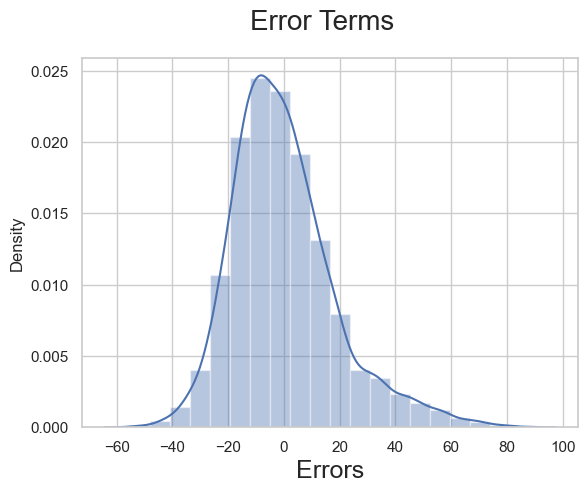

In [283]:
res = y_train-y_train_pred
# Plot the histogram of the error terms
fig = plt.figure()
sns.distplot((res), bins = 20)
fig.suptitle('Error Terms', fontsize = 20)                  # Plot heading 
plt.xlabel('Errors', fontsize = 18)   

In [286]:
col1=X_train_new.columns
X_test=X_test[col1]
# Adding constant variable to test dataframe
X_test_lm3 = sm.add_constant(X_test)
X_test_lm3.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2261 entries, 9420 to 1968
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   const         2261 non-null   float64
 1   temp          2261 non-null   float64
 2   weathersit_3  2261 non-null   uint8  
 3   holiday_1     2261 non-null   uint8  
 4   season_2      2261 non-null   uint8  
 5   hr_Morning    2261 non-null   uint8  
 6   hr_Day        2261 non-null   uint8  
 7   hr_Evening    2261 non-null   uint8  
 8   day_4         2261 non-null   uint8  
 9   day_5         2261 non-null   uint8  
 10  day_6         2261 non-null   uint8  
 11  month_6       2261 non-null   uint8  
 12  month_7       2261 non-null   uint8  
 13  month_10      2261 non-null   uint8  
dtypes: float64(2), uint8(12)
memory usage: 79.5 KB


In [287]:
y_pred = lr3.predict(X_test_lm3)

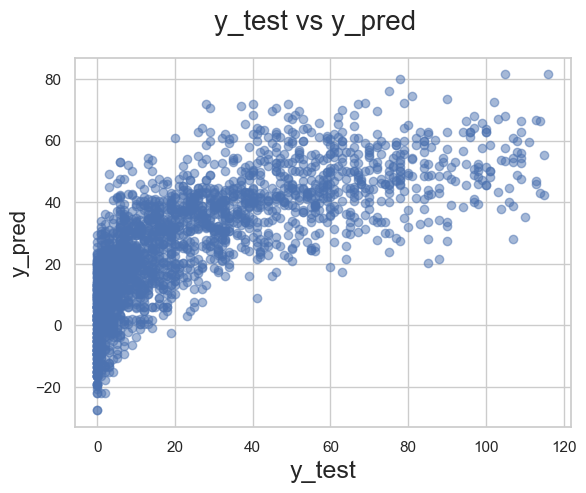

In [288]:
# Plotting y_test and y_pred to understand the spread

fig = plt.figure()
plt.scatter(y_test, y_pred, alpha=.5)
fig.suptitle('y_test vs y_pred', fontsize = 20)              # Plot heading 
plt.xlabel('y_test', fontsize = 18)                          # X-label
plt.ylabel('y_pred', fontsize = 16) 
plt.show()

In [289]:
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

0.5358741266750742

In [290]:
# We already have the value of R^2 (calculated in above step)

r2=0.5358741266750742

In [291]:
n = X_test.shape[0]


# Number of features (predictors, p) is the shape along axis 1
p = X_test.shape[1]

# We find the Adjusted R-squared using the formula

adjusted_r2 = 1-(1-r2)*(n-1)/(n-p-1)
adjusted_r2

0.5331889302561938

In [304]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)



# Print RMSE
print(f"RMSE: {rmse}")
print(f"MAE: {mae}")




RMSE: 18.44865890330667
MAE: 14.200219641856911


In [20]:
bike['hr']

(12165,)